# 주성분 분석

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rickiepark/hg-mldl/blob/master/6-3.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />구글 코랩에서 실행하기</a>
  </td>
</table>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.cluster import KMeans

## PCA 클래스

In [2]:
# !wget https://bit.ly/fruits_300_data -O fruits_300.npy

fruits = np.load('fruits_300.npy')
fruits_2d = fruits.reshape(-1, 100*100)
print(fruits_2d.shape)

(300, 10000)


In [3]:
pca = PCA(n_components=10)  # 300 -> 50 -> 10
pca.fit(fruits_2d)
print(pca.components_.shape)

(10, 10000)


In [4]:
def draw_fruits(arr, ratio=1):
    n = len(arr)    # n은 샘플 개수입니다
    # 한 줄에 10개씩 이미지를 그립니다. 샘플 개수를 10으로 나누어 전체 행 개수를 계산합니다.
    rows = int(np.ceil(n/10))
    # 행이 1개 이면 열 개수는 샘플 개수입니다. 그렇지 않으면 10개입니다.
    cols = n if rows < 2 else 10
    fig, axes = plt.subplots(rows, cols, figsize=(cols*ratio, rows*ratio), squeeze=False)
    for i in range(rows):
        for j in range(cols):
            if i*10 + j < n:    # n 개까지만 그립니다.
                axes[i, j].imshow(arr[i*10 + j], cmap='gray_r')
            axes[i, j].axis('off')
    plt.show()

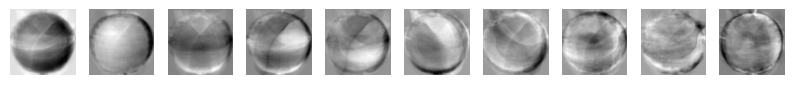

In [5]:
draw_fruits(pca.components_.reshape(-1, 100, 100))

In [6]:
print(fruits_2d.shape)
fruits_pca = pca.transform(fruits_2d)
print(fruits_pca.shape)

(300, 10000)
(300, 10)


## 원본 데이터 재구성

In [7]:
fruits_inverse = pca.inverse_transform(fruits_pca)
print(fruits_inverse.shape)

(300, 10000)


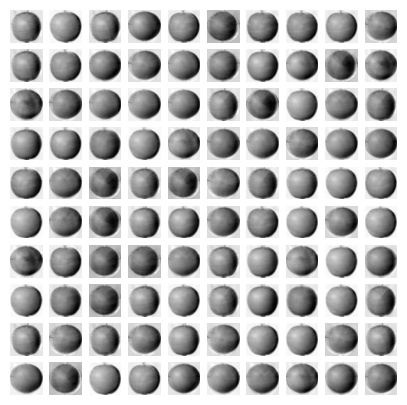

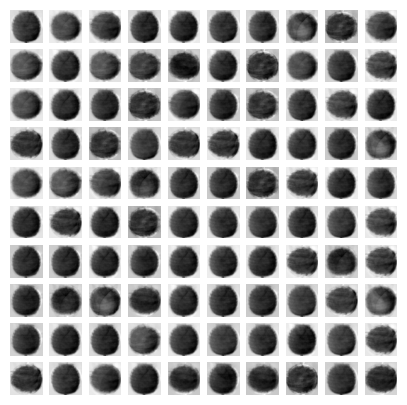

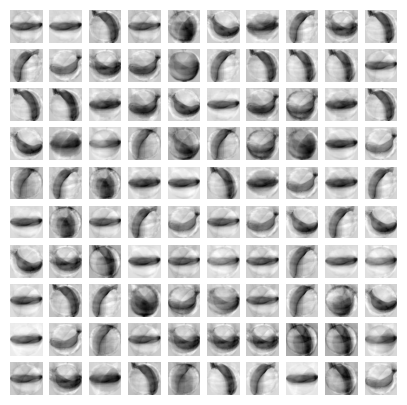

In [8]:
fruits_reconstruct = fruits_inverse.reshape(-1, 100, 100)
for start in [0, 100, 200]:
    draw_fruits(fruits_reconstruct[start:start+100], 0.5)
    print("\n")

## 설명된 분산

0.7694928921071494


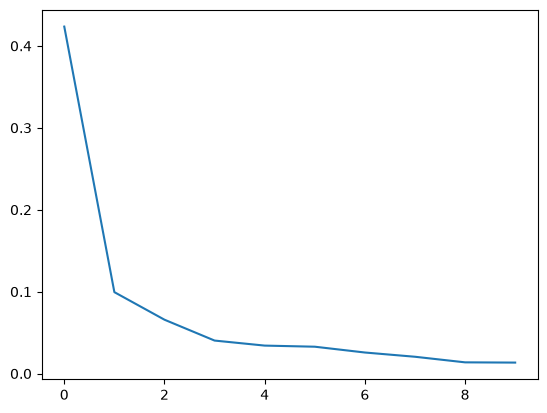

In [9]:
print(np.sum(pca.explained_variance_ratio_))
plt.plot(pca.explained_variance_ratio_)
plt.show()

## 다른 알고리즘과 함께 사용하기

In [10]:
lr = LogisticRegression()
target = np.array([0] * 100 + [1] * 100 + [2] * 100)

In [11]:
scores = cross_validate(lr, fruits_2d, target)
print(np.mean(scores['test_score']))
print(np.mean(scores['fit_time']))

0.9966666666666667
0.11912760734558106


In [12]:
scores = cross_validate(lr, fruits_pca, target)
print(np.mean(scores['test_score']))
print(np.mean(scores['fit_time']))

0.9966666666666667
0.008054256439208984


In [13]:
pca = PCA(n_components=0.5)
pca.fit(fruits_2d)
print(pca.n_components_)
fruits_pca = pca.transform(fruits_2d)
print(fruits_pca.shape)

2
(300, 2)


In [14]:
scores = cross_validate(lr, fruits_pca, target, n_jobs=-1)
print(np.mean(scores['test_score']))
print(np.mean(scores['fit_time']))

0.99
0.019943380355834962


In [15]:
km = KMeans(n_clusters=3, random_state=42)
km.fit(fruits_pca)
print(np.unique(km.labels_, return_counts=True))

(array([0, 1, 2], dtype=int32), array([110,  99,  91]))


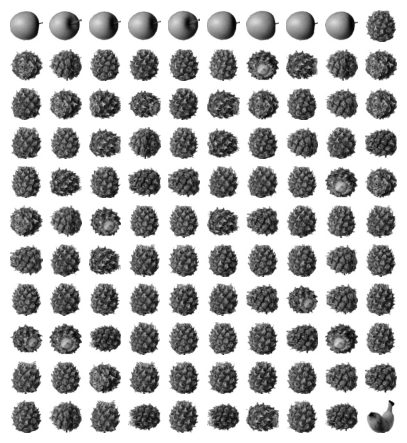

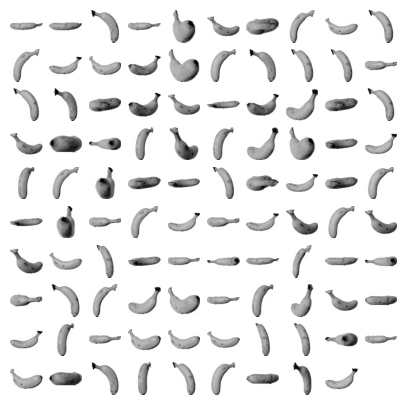

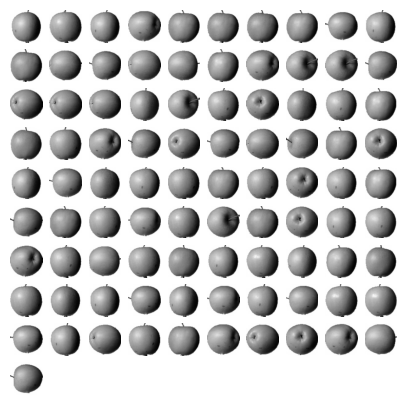

In [16]:
for label in range(0, 3):
    draw_fruits(fruits[km.labels_ == label], 0.5)
    # print("\n")

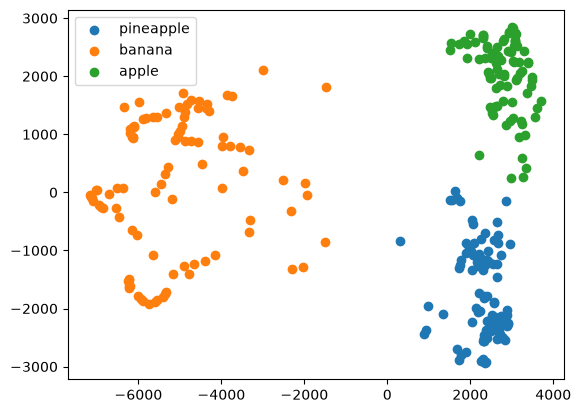

In [17]:
for label in range(0, 3):
    data = fruits_pca[km.labels_ == label]
    plt.scatter(data[:,0], data[:,1])
plt.legend(['pineapple', 'banana', 'apple'])
plt.show()